## 🌐 **Google Drive Connection**

In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/the_reluctants"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/the_reluctants


## ⚙️ **Libraries Import**

In [ ]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.8.0+cu126
Device: cuda


## Parameters and Hyperparameters

In [ ]:
MY_BATCH_SIZE = 64
MY_WINDOW_SIZE = 80
MY_STRIDE = 40

## 🔎 **Exploration and Data Analysis**

In [ ]:
df = pd.read_csv('pirate_pain_train.csv', header=0)

#df = df.drop(columns=["n_legs", "n_hands", "n_eyes"])

#dropping null values if present
df.dropna(axis=0, how='any', inplace=True)

#showing first 10 samples of dataset
df.head(10)

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,0,2,1,two,two,two,1.094705,...,3.499558e-06,1.945042e-06,3.999558e-06,1.153299e-05,0.000004,0.017592,0.013508,0.026798,0.027815,0.5
1,0,1,2,2,2,2,two,two,two,1.135183,...,3.976952e-07,6.765107e-07,6.019627e-06,4.643774e-08,0.000000,0.013352,0.000000,0.013377,0.013716,0.5
2,0,2,2,0,2,2,two,two,two,1.080745,...,1.533820e-07,1.698525e-07,1.446051e-06,2.424536e-06,0.000003,0.016225,0.008110,0.024097,0.023105,0.5
3,0,3,2,2,2,2,two,two,two,0.938017,...,1.006865e-05,5.511079e-07,1.847597e-06,5.432416e-08,0.000000,0.011832,0.007450,0.028613,0.024648,0.5
4,0,4,2,2,2,2,two,two,two,1.090185,...,4.437266e-06,1.735459e-07,1.552722e-06,5.825366e-08,0.000007,0.005360,0.002532,0.033026,0.025328,0.5
5,0,5,2,0,2,1,two,two,two,1.146031,...,1.073167e-06,1.753837e-07,2.957340e-07,6.217311e-08,0.000007,0.006150,0.006444,0.033101,0.023767,0.5
6,0,6,2,1,2,1,two,two,two,1.025870,...,1.074800e-06,1.772156e-07,1.976558e-06,1.576086e-06,0.000005,0.006495,0.006421,0.031804,0.019056,0.5
7,0,7,2,2,2,2,two,two,two,1.038597,...,8.829074e-07,1.790415e-07,2.210562e-06,1.485741e-06,0.000000,0.015998,0.005397,0.035552,0.015732,0.5
8,0,8,2,2,0,1,two,two,two,0.984251,...,1.621055e-06,1.165161e-06,3.030164e-07,5.416678e-07,0.000000,0.020539,0.008517,0.008635,0.015257,0.5
9,0,9,0,2,2,2,two,two,two,1.054999,...,1.609114e-06,3.959558e-06,2.017157e-06,1.154349e-06,0.000007,0.007682,0.021383,0.034006,0.028966,0.5


In [ ]:
#Showing types and count of non null values for every column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  object 
 7   n_hands        105760 non-null  object 
 8   n_eyes         105760 non-null  object 
 9   joint_00       105760 non-null  float64
 10  joint_01       105760 non-null  float64
 11  joint_02       105760 non-null  float64
 12  joint_03       105760 non-null  float64
 13  joint_04       105760 non-null  float64
 14  joint_05       105760 non-null  float64
 15  joint_06       105760 non-null  float64
 16  joint_07       105760 non-null  float64
 17  joint_08       105760 non-nul

In [ ]:
# Generate descriptive statistics for numerical columns in the DataFrame
df.describe()

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,joint_00,joint_01,joint_02,joint_03,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
count,105760.000000,105760.000000,105760.000000,105760.000000,105760.000000,105760.000000,105760.000000,105760.000000,105760.000000,105760.000000,...,1.057600e+05,1.057600e+05,1.057600e+05,1.057600e+05,1.057600e+05,105760.000000,105760.000000,105760.000000,105760.000000,105760.0
mean,330.000000,79.500000,1.633746,1.654851,1.653640,1.663134,0.943095,0.916955,0.779296,0.767921,...,3.972126e-05,4.176794e-05,3.561780e-05,3.138109e-05,1.024604e-04,0.041905,0.058244,0.049886,0.062273,0.5
std,190.814948,46.187338,0.682423,0.669639,0.666649,0.661994,0.202051,0.197608,0.295605,0.300787,...,4.974496e-03,5.472244e-03,1.235450e-03,4.062914e-04,3.206128e-03,0.060293,0.079819,0.060773,0.072597,0.0
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001015,0.005403,...,0.000000e+00,1.510494e-07,0.000000e+00,1.063144e-08,0.000000e+00,0.000203,0.000000,0.000000,0.000000,0.5
25%,165.000000,39.750000,2.000000,2.000000,2.000000,2.000000,0.828277,0.811445,0.568850,0.520020,...,6.545878e-08,3.321650e-07,3.275038e-07,2.841805e-07,7.161332e-07,0.009885,0.012652,0.016290,0.019638,0.5
50%,330.000000,79.500000,2.000000,2.000000,2.000000,2.000000,1.005126,0.979468,0.909549,0.914834,...,8.302747e-07,1.095971e-06,1.024209e-06,8.746147e-07,3.126723e-06,0.021898,0.031739,0.031843,0.039041,0.5
75%,495.000000,119.250000,2.000000,2.000000,2.000000,2.000000,1.081039,1.056611,0.995187,0.994324,...,2.800090e-06,3.079465e-06,3.021830e-06,2.507548e-06,9.946107e-06,0.048579,0.071051,0.058741,0.079518,0.5
max,660.000000,159.000000,2.000000,2.000000,2.000000,2.000000,1.407968,1.334613,1.306046,1.254729,...,1.442198e+00,1.305001e+00,2.742411e-01,3.643074e-02,9.473540e-01,1.223617,1.187419,1.412037,1.370765,0.5


In [ ]:
# Apply One-Hot Encoding to the categorical columns
df = pd.get_dummies(df, columns=['n_legs', 'n_hands', 'n_eyes'], dtype=float)

# Display the first few rows of the DataFrame with the new encoded columns
display(df.head())

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,joint_00,joint_01,joint_02,joint_03,...,joint_27,joint_28,joint_29,joint_30,n_legs_one+peg_leg,n_legs_two,n_hands_one+hook_hand,n_hands_two,n_eyes_one+eye_patch,n_eyes_two
0,0,0,2,0,2,1,1.094705,0.985281,1.018302,1.010385,...,0.013508,0.026798,0.027815,0.5,0.0,1.0,0.0,1.0,0.0,1.0
1,0,1,2,2,2,2,1.135183,1.021175,0.994343,1.052364,...,0.000000,0.013377,0.013716,0.5,0.0,1.0,0.0,1.0,0.0,1.0
2,0,2,2,0,2,2,1.080745,0.962842,1.009588,0.977169,...,0.008110,0.024097,0.023105,0.5,0.0,1.0,0.0,1.0,0.0,1.0
3,0,3,2,2,2,2,0.938017,1.081592,0.998021,0.987283,...,0.007450,0.028613,0.024648,0.5,0.0,1.0,0.0,1.0,0.0,1.0
4,0,4,2,2,2,2,1.090185,1.032145,1.008710,0.963658,...,0.002532,0.033026,0.025328,0.5,0.0,1.0,0.0,1.0,0.0,1.0


In [ ]:
# Display the info to see the new column types and number of columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 43 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   sample_index           105760 non-null  int64  
 1   time                   105760 non-null  int64  
 2   pain_survey_1          105760 non-null  int64  
 3   pain_survey_2          105760 non-null  int64  
 4   pain_survey_3          105760 non-null  int64  
 5   pain_survey_4          105760 non-null  int64  
 6   joint_00               105760 non-null  float64
 7   joint_01               105760 non-null  float64
 8   joint_02               105760 non-null  float64
 9   joint_03               105760 non-null  float64
 10  joint_04               105760 non-null  float64
 11  joint_05               105760 non-null  float64
 12  joint_06               105760 non-null  float64
 13  joint_07               105760 non-null  float64
 14  joint_08               105760 non-nu

In [ ]:
#loading the labels
labelsds=pd.read_csv('pirate_pain_train_labels.csv', header=0)
labelsds.head()

,sample_index,label
0,0,no_pain
1,1,no_pain
2,2,low_pain
3,3,no_pain
4,4,no_pain


In [ ]:
# Get the target values from the Glass dataset
target = labelsds['label'].values
print('Target shape', target.shape)


# Calculate the unique target labels and their counts
unique, count = np.unique(target, return_counts=True)
print('Target labels:', unique)
for i in range(len(unique)):
    print(f'Class {unique[i]} has {count[i]} samples')

Target shape (661,)
Target labels: ['high_pain' 'low_pain' 'no_pain']
Class high_pain has 56 samples
Class low_pain has 94 samples
Class no_pain has 511 samples


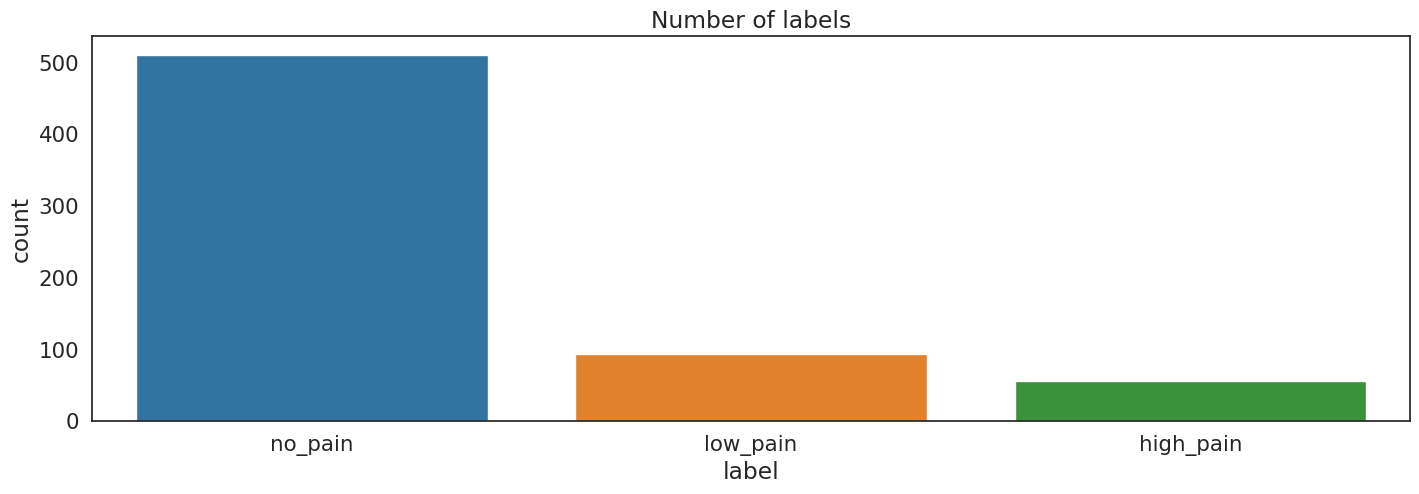

In [ ]:
plt.figure(figsize=(17, 5))
sns.countplot(
    x='label',
    data=labelsds,
    order=labelsds['label'].value_counts().index,
    palette='tab10'
)

# Set the title of the plot
plt.title('Number of labels')

# Display the plot
plt.show()

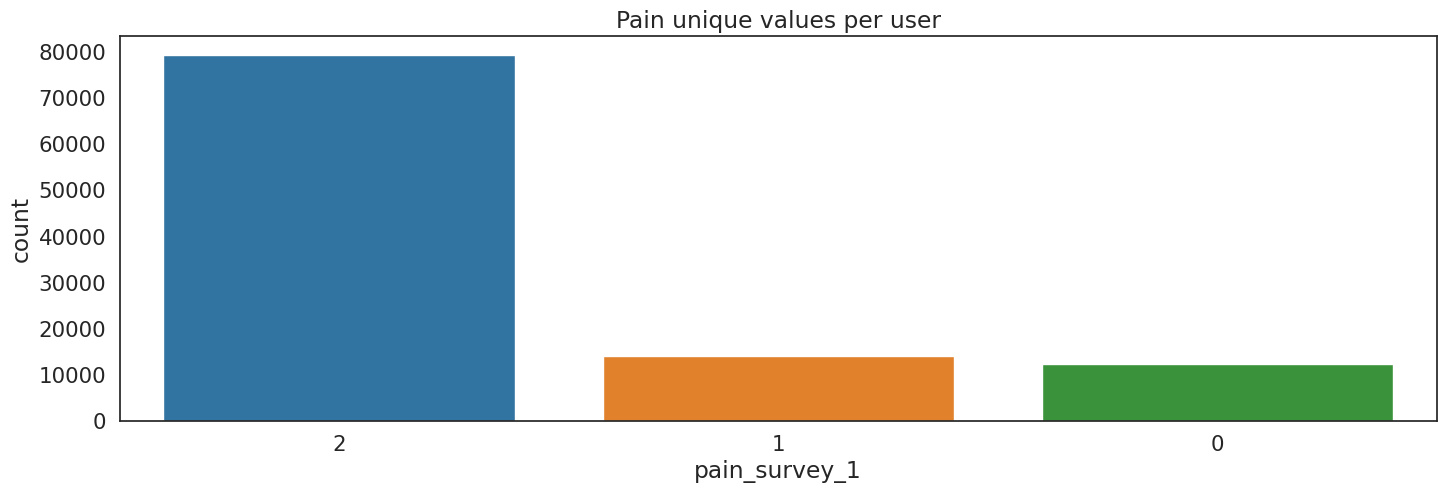

In [ ]:
plt.figure(figsize=(17, 5))
sns.countplot(
    x='pain_survey_1',
    data=df,
    order=df['pain_survey_1'].value_counts().index,
    palette='tab10'
)

# Set the title of the plot
plt.title('Pain unique values per user')

# Display the plot
plt.show()

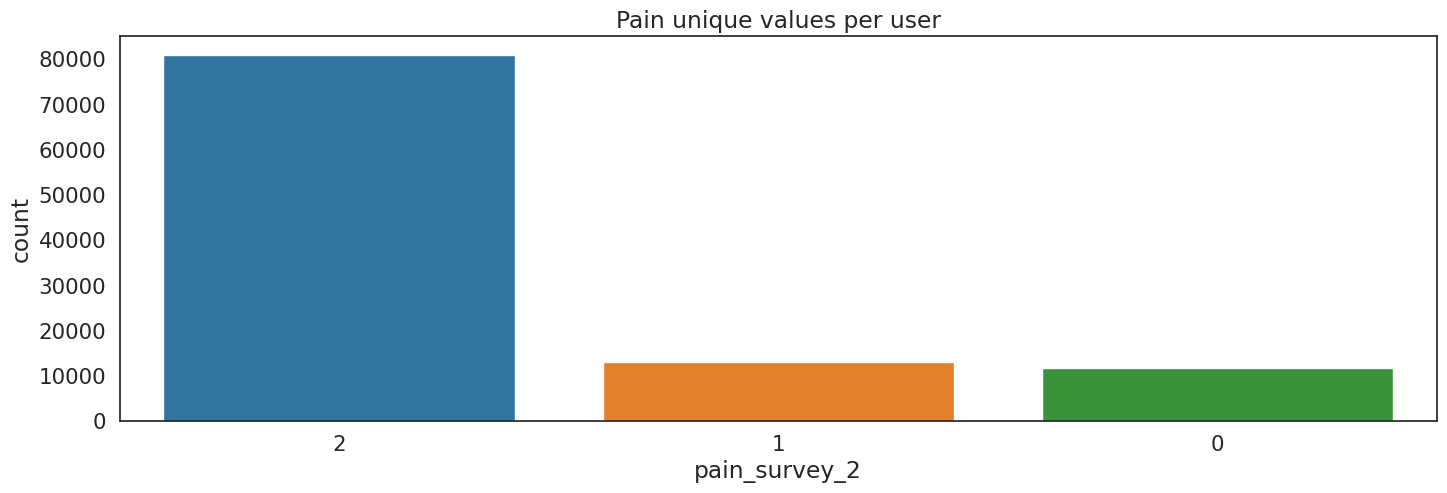

In [ ]:
plt.figure(figsize=(17, 5))
sns.countplot(
    x='pain_survey_2',
    data=df,
    order=df['pain_survey_2'].value_counts().index,
    palette='tab10'
)

# Set the title of the plot
plt.title('Pain unique values per user')

# Display the plot
plt.show()

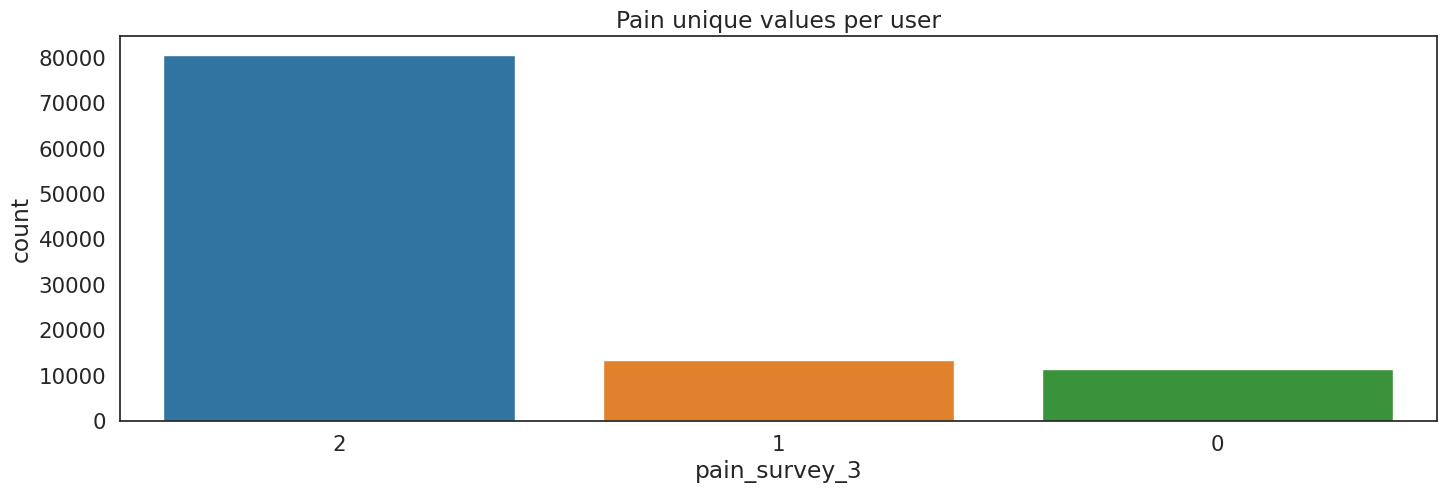

In [ ]:
plt.figure(figsize=(17, 5))
sns.countplot(
    x='pain_survey_3',
    data=df,
    order=df['pain_survey_3'].value_counts().index,
    palette='tab10'
)

# Set the title of the plot
plt.title('Pain unique values per user')

# Display the plot
plt.show()

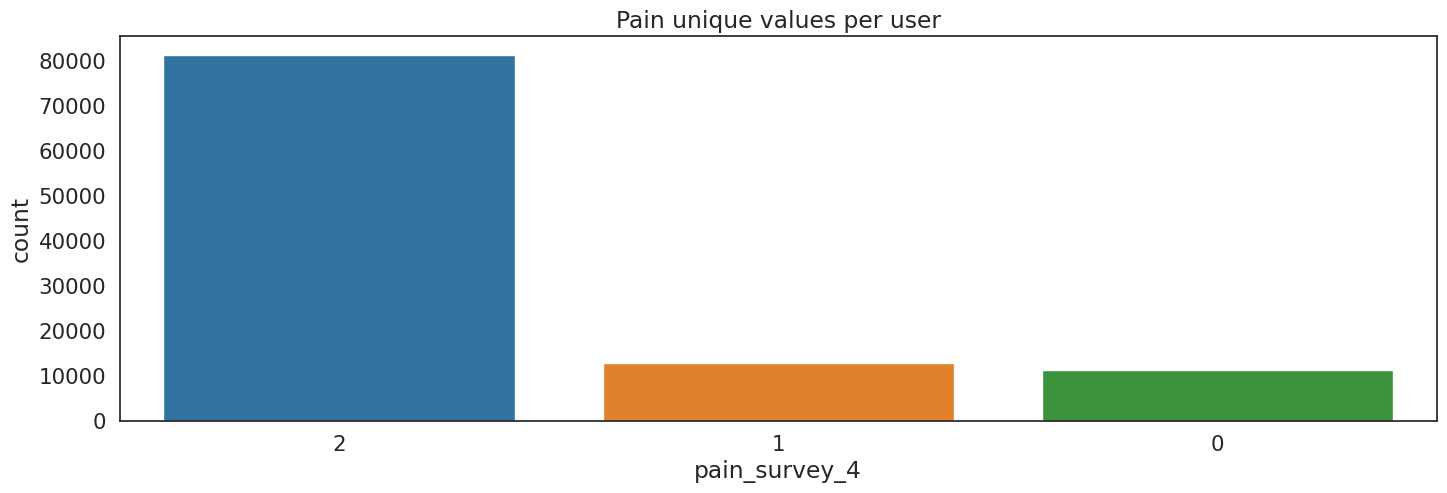

In [ ]:
plt.figure(figsize=(17, 5))
sns.countplot(
    x='pain_survey_4',
    data=df,
    order=df['pain_survey_4'].value_counts().index,
    palette='tab10'
)

# Set the title of the plot
plt.title('Pain unique values per user')

# Display the plot
plt.show()

In [ ]:
df = pd.merge(df, labelsds, on='sample_index', how='inner')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 44 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   sample_index           105760 non-null  int64  
 1   time                   105760 non-null  int64  
 2   pain_survey_1          105760 non-null  int64  
 3   pain_survey_2          105760 non-null  int64  
 4   pain_survey_3          105760 non-null  int64  
 5   pain_survey_4          105760 non-null  int64  
 6   joint_00               105760 non-null  float64
 7   joint_01               105760 non-null  float64
 8   joint_02               105760 non-null  float64
 9   joint_03               105760 non-null  float64
 10  joint_04               105760 non-null  float64
 11  joint_05               105760 non-null  float64
 12  joint_06               105760 non-null  float64
 13  joint_07               105760 non-null  float64
 14  joint_08               105760 non-nu

In [ ]:
# Define the mapping for the 'label' column
label_mapping = {
    'no_pain': 2,
    'low_pain': 1,
    'high_pain': 0
}

# Apply the mapping to the 'label' column
df['label'] = df['label'].map(label_mapping)

# Display the first few rows to verify the changes
df.head()

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,joint_00,joint_01,joint_02,joint_03,...,joint_28,joint_29,joint_30,n_legs_one+peg_leg,n_legs_two,n_hands_one+hook_hand,n_hands_two,n_eyes_one+eye_patch,n_eyes_two,label
0,0,0,2,0,2,1,1.094705,0.985281,1.018302,1.010385,...,0.026798,0.027815,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
1,0,1,2,2,2,2,1.135183,1.021175,0.994343,1.052364,...,0.013377,0.013716,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
2,0,2,2,0,2,2,1.080745,0.962842,1.009588,0.977169,...,0.024097,0.023105,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
3,0,3,2,2,2,2,0.938017,1.081592,0.998021,0.987283,...,0.028613,0.024648,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
4,0,4,2,2,2,2,1.090185,1.032145,1.008710,0.963658,...,0.033026,0.025328,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2


In [ ]:
for col in df.columns:
    if col not in ['time', 'sample_index', 'label']:
        df[col] = df[col].astype(np.float32)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 44 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   sample_index           105760 non-null  int64  
 1   time                   105760 non-null  int64  
 2   pain_survey_1          105760 non-null  float32
 3   pain_survey_2          105760 non-null  float32
 4   pain_survey_3          105760 non-null  float32
 5   pain_survey_4          105760 non-null  float32
 6   joint_00               105760 non-null  float32
 7   joint_01               105760 non-null  float32
 8   joint_02               105760 non-null  float32
 9   joint_03               105760 non-null  float32
 10  joint_04               105760 non-null  float32
 11  joint_05               105760 non-null  float32
 12  joint_06               105760 non-null  float32
 13  joint_07               105760 non-null  float32
 14  joint_08               105760 non-nu

In [ ]:
# Get unique user IDs and shuffle them
unique_users = df['sample_index'].unique()
random.seed(SEED) # Ensure reproducibility of shuffling
random.shuffle(unique_users)

# Define the number of users for validation and test sets
N_VAL_USERS = int(0.2 * len(unique_users)) # Convert to integer

# Calculate the number of users for the training set
n_train_users = len(unique_users) - N_VAL_USERS

# Split the shuffled user IDs into training, validation, and test sets
train_users = unique_users[:n_train_users]
val_users = unique_users[n_train_users:]

# Split the dataset into training, validation, and test sets based on user IDs
df_train = df[df['sample_index'].isin(train_users)] # Corrected column name
df_val = df[df['sample_index'].isin(val_users)] # Corrected column name

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')

Training set shape: (84640, 44)
Validation set shape: (21120, 44)


In [ ]:
# Initialise a dictionary to count occurrences of each activity in the training set
training_labels = {
    '2' : 0,
    '1' : 0,
    '0' : 0
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = str(df_train[df_train['sample_index'] == id]['label'].values[0])
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'2': 409, '1': 75, '0': 45}


In [ ]:
# Initialise a dictionary to count occurrences of each activity in the training set
validation_labels = {
    '2' : 0,
    '1' : 0,
    '0' : 0
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_val['sample_index'].unique():
    label = str(df_val[df_val['sample_index'] == id]['label'].values[0])
    validation_labels[label] += 1

# Print the distribution of training labels
print('validation labels:', validation_labels)

validation labels: {'2': 102, '1': 19, '0': 11}


In [ ]:
# Define the columns to be normalised (joint features)
joint_columns = [f'joint_{i:02d}' for i in range(30)]

# Calculate the minimum and maximum values from the training data only
mins = df_train[joint_columns].min()
maxs = df_train[joint_columns].max()

# Apply normalisation to the specified joint columns in all datasets
for column in joint_columns:
    # Normalise the training set
    df_train[column] = (df_train[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the validation set
    df_val[column] = (df_val[column] - mins[column]) / (maxs[column] - mins[column])

In [ ]:
# Display the first five rows of the training DataFrame
print(df_train.shape)
df_train.head()

(84640, 44)


,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,joint_00,joint_01,joint_02,joint_03,...,joint_28,joint_29,joint_30,n_legs_one+peg_leg,n_legs_two,n_hands_one+hook_hand,n_hands_two,n_eyes_one+eye_patch,n_eyes_two,label
0,0,0,2.0,0.0,2.0,1.0,0.777507,0.738252,0.779485,0.804419,...,0.018978,0.020291,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
1,0,1,2.0,2.0,2.0,2.0,0.806256,0.765147,0.761124,0.838021,...,0.009473,0.010006,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
2,0,2,2.0,0.0,2.0,2.0,0.767592,0.721439,0.772806,0.777832,...,0.017065,0.016856,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
3,0,3,2.0,2.0,2.0,2.0,0.666220,0.810416,0.763942,0.785928,...,0.020264,0.017981,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2
4,0,4,2.0,2.0,2.0,2.0,0.774297,0.773366,0.772134,0.767017,...,0.023389,0.018477,0.5,0.0,1.0,0.0,1.0,0.0,1.0,2


<h3> Checking for NaN values in other columns, after noting that joint_30 has always the same value </h3>

In [ ]:
# Define the joint columns again to ensure consistency
joint_columns_to_check = [f'joint_{i:02d}' for i in range(30)]

print("NaN values in df_train joint columns:")
display(df_train[joint_columns_to_check].isna().sum()[df_train[joint_columns_to_check].isna().sum() > 0])

print("\nNaN values in df_val joint columns:")
display(df_val[joint_columns_to_check].isna().sum()[df_val[joint_columns_to_check].isna().sum() > 0])

NaN values in df_train joint columns:


,0



NaN values in df_val joint columns:


,0


In [ ]:
# Define the window size
WINDOW_SIZE = MY_WINDOW_SIZE

# Define the stride for overlapping windows
STRIDE = MY_STRIDE

In [ ]:
# Define a function to build sequences from the dataset
def build_sequences(df, window=10, stride=10):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    hasLabels = 'label' in df.columns

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Define the columns to be used for features
    joint_columns = [f'joint_{i:02d}' for i in range(31)]
    pain_survey_columns = [f'pain_survey_{i}' for i in range(1, 5)]
    categorical_columns = ['n_legs_one+peg_leg', 'n_legs_two', 'n_hands_one+hook_hand', 'n_hands_two', 'n_eyes_one+eye_patch', 'n_eyes_two']

    feature_columns = joint_columns + pain_survey_columns + categorical_columns

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract features for the current ID
        temp = df[df['sample_index'] == id][feature_columns].values

        # Retrieve the label for the current ID
        if hasLabels:
          label = df[df['sample_index'] == id]['label'].values[0]

        # Calculate padding length to ensure full windows
        #if len(temp) % window != 0:
        #  padding_len = window - len(temp) % window
        #else:
         # padding_len = 0
        padding_len = (window - len(temp) % window) % window


        # Create zero padding and concatenate with the data
        # The padding should match the number of feature columns
        padding = np.zeros((padding_len, len(feature_columns)), dtype='float32')
        temp = np.concatenate((temp, padding))


        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            if hasLabels:
              labels.append(label)
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    if hasLabels:
      labels = np.array(labels)

    return dataset, labels

In [ ]:
# Generate sequences and labels for the training set
X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the validation set
X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

X_train.shape, y_train.shape, X_val.shape, y_val.shape

((1587, 80, 41), (1587,), (396, 80, 41), (396,))

In [ ]:
# Define the input shape based on the training data
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

In [ ]:
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))

In [ ]:
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE = MY_BATCH_SIZE

In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [ ]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
# @title
# Get one batch from the training data loader
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([64, 80, 41])
Labels batch shape: torch.Size([64])


## 🛠️ **Model Building**




In [ ]:
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha # Weighting factor for classes
        self.gamma = gamma # Focusing parameter
        self.reduction = reduction

    def forward(self, inputs, targets):
        # Inputs are the raw logits from the model
        # Targets are the ground truth class indices

        # Compute the Cross-Entropy Loss
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')

        # Compute the probability of the ground truth class
        pt = torch.exp(-ce_loss)

        # Compute the Focal Loss
        # The alpha term weights the classes, and the (1-pt)**gamma term reduces
        # the loss for easy examples (those with high probability pt)
        focal_loss = (1 - pt) ** self.gamma * ce_loss

        # Apply alpha if provided (weighted loss for classes)
        if self.alpha is not None:
            if not isinstance(self.alpha, torch.Tensor):
                self.alpha = torch.tensor(self.alpha, dtype=inputs.dtype, device=inputs.device)
            alpha_t = self.alpha.gather(0, targets.data.view(-1))
            focal_loss = alpha_t * focal_loss

        # Apply reduction
        if self.reduction == 'mean':
            return torch.mean(focal_loss)
        elif self.reduction == 'sum':
            return torch.sum(focal_loss)
        else: # 'none' or 'batchmean' (not explicitly handled but default CE behavior)
            return focal_loss

In [ ]:
# @title
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

In [ ]:
class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='GRU',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,
            dropout_rate=0.2
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        # Map string name to PyTorch RNN class
        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        # Dropout is only applied between layers (if num_layers > 1)
        dropout_val = dropout_rate if num_layers > 1 else 0

        # Create the recurrent layer
        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,       # Input shape: (batch, seq_len, features)
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # Calculate input size for the final classifier
        if self.bidirectional:
            classifier_input_size = hidden_size * 2 # Concat fwd + bwd
        else:
            classifier_input_size = hidden_size

        # Final classification layer
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x):
        """
        x shape: (batch_size, seq_length, input_size)
        """

        # rnn_out shape: (batch_size, seq_len, hidden_size * num_directions)
        rnn_out, hidden = self.rnn(x)

        # LSTM returns (h_n, c_n), we only need h_n
        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        # hidden shape: (num_layers * num_directions, batch_size, hidden_size)

        if self.bidirectional:
            # Reshape to (num_layers, 2, batch_size, hidden_size)
            hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)

            # Concat last fwd (hidden[-1, 0, ...]) and bwd (hidden[-1, 1, ...])
            # Final shape: (batch_size, hidden_size * 2)
            hidden_to_classify = torch.cat([hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1)
        else:
            # Take the last layer's hidden state
            # Final shape: (batch_size, hidden_size)
            hidden_to_classify = hidden[-1]

        # Get logits
        logits = self.classifier(hidden_to_classify)
        return logits

## 🧮 **Network and Training Hyperparameters**

In [ ]:
import numpy as np

# Training configuration
LEARNING_RATE = 1e-3
EPOCHS = 500
PATIENCE = 50

# Architecture
HIDDEN_LAYERS = 2        # Hidden layers
HIDDEN_SIZE = 128        # Neurons per layer

# Regularisation
DROPOUT_RATE = 0.2         # Dropout probability
L1_LAMBDA = 0            # L1 penalty
L2_LAMBDA = 5e-5            # L2 penalty

# Calculate class weights based on original label distribution
# (high_pain: 0, low_pain: 1, no_pain: 2)
class_counts = np.array([56, 94, 511]) # Counts for labels 0, 1, 2 respectively
class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum() # Normalize weights

# Convert to PyTorch tensor
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

# Set up loss function and optimizer
criterion = FocalLoss(alpha=class_weights_tensor, gamma=2.0, reduction='mean')

## 🧠 **Model Training Preparation**

In [ ]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [ ]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [ ]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [ ]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

# Cross Validation & Grid Search
Perform k-fold cross-validation and grid search to find the best hyperparameters for the model.

## Prepare data for k-fold cross-validation


**Reasoning**:
Combine the training and validation dataframes and then generate the cross-validation folds using KFold on the unique sample indices.



In [ ]:
# Combine train and validation dataframes
df_combined = pd.concat([df_train, df_val], ignore_index=True)

# Get unique sample indices from the combined DataFrame
unique_users_combined = df_combined['sample_index'].unique()

# Import KFold
from sklearn.model_selection import KFold

# Instantiate KFold with 5 splits, shuffling and the predefined seed
kf = KFold(n_splits=3, shuffle=True, random_state=SEED)

# Generate folds using the split method on the unique sample indices
folds = list(kf.split(unique_users_combined))

print(f"Number of unique users in combined data: {len(unique_users_combined)}")
print(f"Number of folds generated: {len(folds)}")

Number of unique users in combined data: 661
Number of folds generated: 3


## Implement k-fold cross-validation loop


Here we are implementing a loop that iterates through each fold, then training and evaluating the model. This cell was also used to train a model in order to make sure that the cross validation worked, but that part has now been commented out



In [ ]:
fold_results = []

for fold_idx, (train_indices, val_indices) in enumerate(folds):
    print(f"--- Starting Fold {fold_idx + 1}/{kf.n_splits} ---")

    # 2. Split the combined dataframe into training and validation sets based on user indices
    train_users_fold = unique_users_combined[train_indices]
    val_users_fold = unique_users_combined[val_indices]

    df_train_fold = df_combined[df_combined['sample_index'].isin(train_users_fold)]
    df_val_fold = df_combined[df_combined['sample_index'].isin(val_users_fold)]

    # Apply normalisation to the specified joint columns in all datasets
    joint_columns = [f'joint_{i:02d}' for i in range(30)]
    mins_fold = df_train_fold[joint_columns].min()
    maxs_fold = df_train_fold[joint_columns].max()

    for column in joint_columns:
        df_train_fold[column] = (df_train_fold[column] - mins_fold[column]) / (maxs_fold[column] - mins_fold[column])
        df_val_fold[column] = (df_val_fold[column] - mins_fold[column]) / (maxs_fold[column] - mins_fold[column])


    # 3. Generate sequences and labels for the training and validation dataframes
    X_train_fold, y_train_fold = build_sequences(df_train_fold, WINDOW_SIZE, STRIDE)
    X_val_fold, y_val_fold = build_sequences(df_val_fold, WINDOW_SIZE, STRIDE)

    # 4. Create PyTorch TensorDatasets
    train_ds_fold = TensorDataset(torch.from_numpy(X_train_fold).float(), torch.from_numpy(y_train_fold).long())
    val_ds_fold = TensorDataset(torch.from_numpy(X_val_fold).float(), torch.from_numpy(y_val_fold).long())

    # 5. Create PyTorch DataLoaders
    train_loader_fold = make_loader(train_ds_fold, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
    val_loader_fold = make_loader(val_ds_fold, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

#     # 6. Instantiate the RecurrentClassifier model
#     model_fold = RecurrentClassifier(
#         input_size=input_shape[-1],
#         hidden_size=HIDDEN_SIZE,
#         num_layers=HIDDEN_LAYERS,
#         num_classes=num_classes,
#         dropout_rate=DROPOUT_RATE,
#         bidirectional=True,
#         rnn_type='LSTM'
#     ).to(device)

#     # 7. Define the optimizer
#     optimizer_fold = torch.optim.AdamW(model_fold.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

#     # 8. Initialize the gradient scaler
#     scaler_fold = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

#     # 9. Train the model
#     # Using a temporary writer for each fold if needed for detailed logging per fold
#     # For overall grid search, aggregate results and log at the end.
#     # Setting verbose to a higher value or 0 to reduce output during grid search
#     model_fold, history_fold = fit(
#         model=model_fold,
#         train_loader=train_loader_fold,
#         val_loader=val_loader_fold,
#         epochs=EPOCHS,
#         criterion=criterion,
#         optimizer=optimizer_fold,
#         scaler=scaler_fold,
#         device=device,
#         writer=None, # No individual fold logging for simplicity
#         verbose=1,
#         experiment_name=f"fold_{fold_idx+1}_temp", # Temporary name
#         patience=PATIENCE
#     )

#     # 10. Store the validation F1 score
#     best_val_f1_fold = max(history_fold['val_f1']) # Assuming 'val_f1' is the metric
#     fold_results.append(best_val_f1_fold)

#     print(f"--- Fold {fold_idx + 1} Finished. Best Validation F1: {best_val_f1_fold:.4f} ---")

# # Print average performance across folds
# print(f"\nAverage Validation F1 across {kf.n_splits} folds: {np.mean(fold_results):.4f}")

--- Starting Fold 1/3 ---
--- Starting Fold 2/3 ---
--- Starting Fold 3/3 ---


## Define Hyperparameter Grid

We define a dictionary where keys are hyperparameter names and values are lists of values to try for each hyperparameter.

In [ ]:
# Define the hyperparameter grid
param_grid = {
    'DROPOUT_RATE': [0.1, 0.3, 0.6], # Reduced values
    'LEARNING_RATE': [1e-3], # Reduced values
    'L2_LAMBDA': [1e-4], # Reduced values
    'BATCH_SIZE': [64], # Reduced values
    'WINDOW_SIZE': [20], # Reduced values
    'STRIDE': [10] # Reduced values to ensure divisibility with WINDOW_SIZE
}

## Implement Grid Search Loop

We generate all combinations of hyperparameters from the defined grid and then loop through each combination.

In [ ]:
from itertools import product

best_mean_f1 = float('-inf')
best_hyperparams = None
all_results = []

hyperparameter_combinations = list(product(*param_grid.values()))

for i, combo in enumerate(hyperparameter_combinations):
    current_hyperparams = dict(zip(param_grid.keys(), combo))

    print(f"\n--- Starting Grid Search Iteration {i + 1}/{len(hyperparameter_combinations)} ---")
    print(f"Current Hyperparameters: {current_hyperparams}")

    fold_results = []
    for fold_idx, (train_indices, val_indices) in enumerate(folds):
        train_users_fold = unique_users_combined[train_indices]
        val_users_fold = unique_users_combined[val_indices]

        df_train_fold = df_combined[df_combined['sample_index'].isin(train_users_fold)].copy()
        df_val_fold = df_combined[df_combined['sample_index'].isin(val_users_fold)].copy()


        joint_columns = [f'joint_{i:02d}' for i in range(30)]
        mins_fold = df_train_fold[joint_columns].min()
        maxs_fold = df_train_fold[joint_columns].max()

        for column in joint_columns:
            df_train_fold[column] = (df_train_fold[column] - mins_fold[column]) / (maxs_fold[column] - mins_fold[column])
            df_val_fold[column] = (df_val_fold[column] - mins_fold[column]) / (maxs_fold[column] - mins_fold[column])


        X_train_fold, y_train_fold = build_sequences(df_train_fold, current_hyperparams['WINDOW_SIZE'], current_hyperparams['STRIDE'])
        X_val_fold, y_val_fold = build_sequences(df_val_fold, current_hyperparams['WINDOW_SIZE'], current_hyperparams['STRIDE'])

        train_ds_fold = TensorDataset(torch.from_numpy(X_train_fold).float(), torch.from_numpy(y_train_fold).long())
        val_ds_fold = TensorDataset(torch.from_numpy(X_val_fold).float(), torch.from_numpy(y_val_fold).long())


        train_loader_fold = make_loader(train_ds_fold, batch_size=current_hyperparams['BATCH_SIZE'], shuffle=True, drop_last=False)
        val_loader_fold = make_loader(val_ds_fold, batch_size=current_hyperparams['BATCH_SIZE'], shuffle=False, drop_last=False)


        model_fold = RecurrentClassifier(
            input_size=input_shape[-1],
            hidden_size=HIDDEN_SIZE, # Use global HIDDEN_SIZE
            num_layers=HIDDEN_LAYERS, # Use global HIDDEN_LAYERS
            num_classes=num_classes,
            dropout_rate=current_hyperparams['DROPOUT_RATE'],
            bidirectional=True,
            rnn_type='LSTM'
        ).to(device)

        optimizer_fold = torch.optim.AdamW(
            model_fold.parameters(),
            lr=current_hyperparams['LEARNING_RATE'],
            weight_decay=current_hyperparams['L2_LAMBDA']
        )

        scaler_fold = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        model_fold, history_fold = fit(
            model=model_fold,
            train_loader=train_loader_fold,
            val_loader=val_loader_fold,
            epochs=EPOCHS,
            criterion=criterion,
            optimizer=optimizer_fold,
            scaler=scaler_fold,
            device=device,
            writer=None,
            verbose=0,
            experiment_name=f"grid_search_fold_{fold_idx+1}_{i+1}",
            patience=PATIENCE
        )

        best_val_f1_fold = max(history_fold['val_f1'])
        fold_results.append(best_val_f1_fold)

        print(f"Fold {fold_idx + 1} Finished. Best Validation F1: {best_val_f1_fold:.4f}")

    mean_f1_across_folds = np.mean(fold_results)
    print(f"Mean Validation F1 across folds: {mean_f1_across_folds:.4f}")

    all_results.append({
        'hyperparameters': current_hyperparams,
        'mean_f1': mean_f1_across_folds,
        'fold_f1s': fold_results
    })

    if mean_f1_across_folds > best_mean_f1:
        best_mean_f1 = mean_f1_across_folds
        best_hyperparams = current_hyperparams
        print("Found new best hyperparameters!")

print("\n--- Grid Search Complete ---")
print(f"Best Mean Validation F1: {best_mean_f1:.4f}")
print(f"Best Hyperparameters: {best_hyperparams}")


--- Starting Grid Search Iteration 1/3 ---
Current Hyperparameters: {'DROPOUT_RATE': 0.1, 'LEARNING_RATE': 0.001, 'L2_LAMBDA': 0.0001, 'BATCH_SIZE': 64, 'WINDOW_SIZE': 20, 'STRIDE': 10}
Training 500 epochs...
Early stopping triggered after 95 epochs.
Best model restored from epoch 45 with val_f1 0.9303
Fold 1 Finished. Best Validation F1: 0.9303
Training 500 epochs...
Early stopping triggered after 160 epochs.
Best model restored from epoch 110 with val_f1 0.9372
Fold 2 Finished. Best Validation F1: 0.9372
Training 500 epochs...
Early stopping triggered after 177 epochs.
Best model restored from epoch 127 with val_f1 0.9211
Fold 3 Finished. Best Validation F1: 0.9211
Mean Validation F1 across folds: 0.9295
Found new best hyperparameters!

--- Starting Grid Search Iteration 2/3 ---
Current Hyperparameters: {'DROPOUT_RATE': 0.3, 'LEARNING_RATE': 0.001, 'L2_LAMBDA': 0.0001, 'BATCH_SIZE': 64, 'WINDOW_SIZE': 20, 'STRIDE': 10}
Training 500 epochs...
Early stopping triggered after 258 epochs

## Train Final Model with Best Hyperparameters

We train the final model on the entire combined training and validation dataset using the best hyperparameters found during the grid search.

**Reasoning**:
Instantiate the model with the `best_hyperparams` and train it on `df_combined`.

In [ ]:
# Instantiate the final model with the best hyperparameters
final_model = RecurrentClassifier(
    input_size=input_shape[-1],
    hidden_size=HIDDEN_SIZE, # Use global HIDDEN_SIZE
    num_layers=HIDDEN_LAYERS, # Use global HIDDEN_LAYERS
    num_classes=num_classes,
    dropout_rate=best_hyperparams['DROPOUT_RATE'],
    bidirectional=True,
    rnn_type='LSTM'
).to(device)

# Define the optimizer for the final model with the best hyperparameters
final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=best_hyperparams['LEARNING_RATE'],
    weight_decay=best_hyperparams['L2_LAMBDA']
)

# Initialize the gradient scaler for the final model
final_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Create a DataLoader for the entire combined training and validation dataset
# We need to rebuild sequences and datasets from df_combined
# Apply normalisation to the specified joint columns in all datasets
joint_columns = [f'joint_{i:02d}' for i in range(30)]
mins_combined = df_combined[joint_columns].min()
maxs_combined = df_combined[joint_columns].max()

df_combined_normalized = df_combined.copy() # Create a copy to avoid modifying original df_combined

for column in joint_columns:
    df_combined_normalized[column] = (df_combined_normalized[column] - mins_combined[column]) / (maxs_combined[column] - mins_combined[column])


X_combined, y_combined = build_sequences(df_combined_normalized, best_hyperparams['WINDOW_SIZE'], best_hyperparams['STRIDE'])
combined_ds = TensorDataset(torch.from_numpy(X_combined).float(), torch.from_numpy(y_combined).long())
combined_loader = make_loader(combined_ds, batch_size=best_hyperparams['BATCH_SIZE'], shuffle=True, drop_last=False)


print("Training final model with best hyperparameters...")
# Train the final model on the combined dataset
final_model, final_training_history = fit(
    model=final_model,
    train_loader=combined_loader, # Use the combined loader for training
    val_loader=val_loader, # Still use val_loader for monitoring during training if needed, or create a dummy one
    epochs=EPOCHS, # You might want to adjust epochs or patience here
    criterion=criterion,
    optimizer=final_optimizer,
    scaler=final_scaler,
    device=device,
    writer=None, # No TensorBoard logging for this final training run
    verbose=1, # Print progress during final training
    experiment_name="final_model_best_hps", # Name for saving the final model
    patience=50 # Use patience for early stopping
)

print("\nFinal model training complete.")

Training final model with best hyperparameters...
Training 500 epochs...
Epoch   1/500 | Train: Loss=0.0648, F1 Score=0.6021 | Val: Loss=0.0606, F1 Score=0.7273
Epoch   2/500 | Train: Loss=0.0482, F1 Score=0.7526 | Val: Loss=0.0536, F1 Score=0.6296
Epoch   3/500 | Train: Loss=0.0389, F1 Score=0.7873 | Val: Loss=0.0405, F1 Score=0.6441
Epoch   4/500 | Train: Loss=0.0316, F1 Score=0.8206 | Val: Loss=0.0270, F1 Score=0.6311
Epoch   5/500 | Train: Loss=0.0275, F1 Score=0.8177 | Val: Loss=0.0282, F1 Score=0.8346
Epoch   6/500 | Train: Loss=0.0232, F1 Score=0.8465 | Val: Loss=0.0430, F1 Score=0.7473
Epoch   7/500 | Train: Loss=0.0215, F1 Score=0.8678 | Val: Loss=0.0319, F1 Score=0.6635
Epoch   8/500 | Train: Loss=0.0209, F1 Score=0.8600 | Val: Loss=0.0294, F1 Score=0.7647
Epoch   9/500 | Train: Loss=0.0173, F1 Score=0.8841 | Val: Loss=0.0308, F1 Score=0.6764
Epoch  10/500 | Train: Loss=0.0150, F1 Score=0.8868 | Val: Loss=0.0289, F1 Score=0.8815
Epoch  11/500 | Train: Loss=0.0182, F1 Score=0.

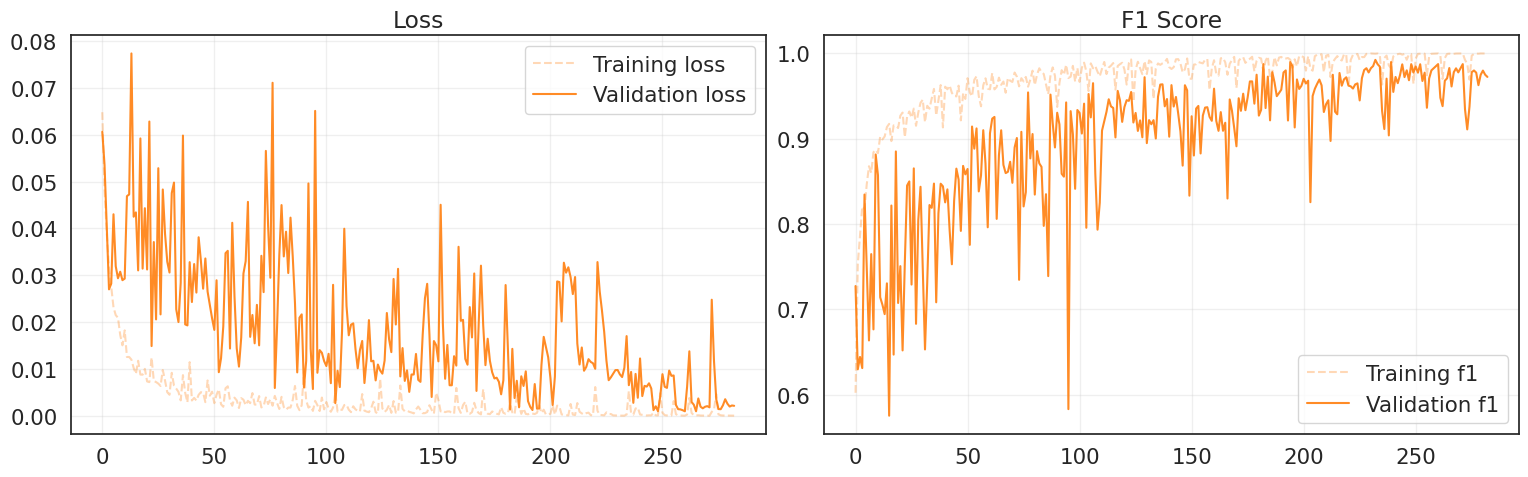

In [ ]:
# @title
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(final_training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(final_training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(final_training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(final_training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 1.0000
Precision over the validation set: 1.0000
Recall over the validation set: 1.0000
F1 score over the validation set: 1.0000


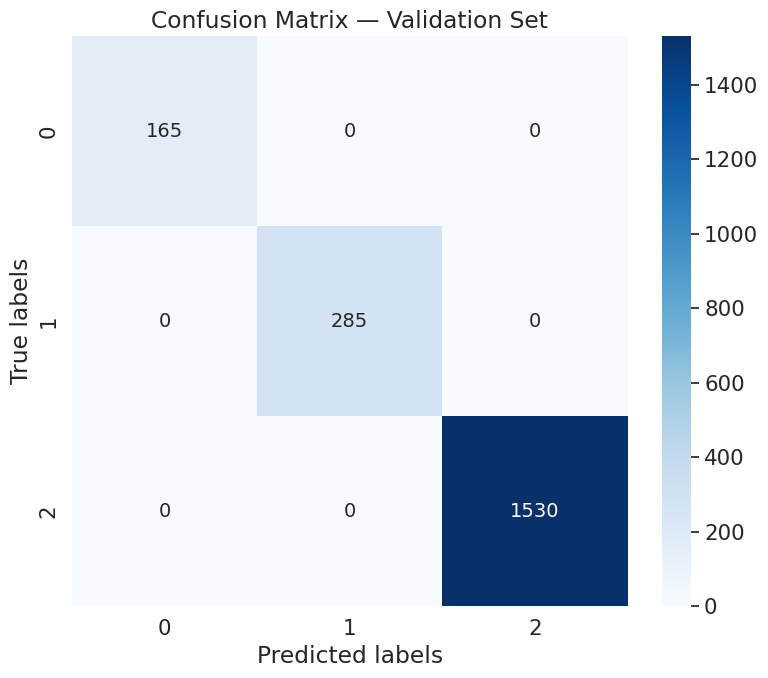

In [ ]:
# @title Plot Confusion Matrix

# Recreate val_loader with best hyperparameters for consistent evaluation
X_val_for_eval, y_val_for_eval = build_sequences(df_val, best_hyperparams['WINDOW_SIZE'], best_hyperparams['STRIDE'])
val_ds_for_eval = TensorDataset(torch.from_numpy(X_val_for_eval).float(), torch.from_numpy(y_val_for_eval).long())
val_loader_for_eval = make_loader(val_ds_for_eval, batch_size=best_hyperparams['BATCH_SIZE'], shuffle=False, drop_last=False)

# Collect predictions and ground truth labels
val_preds, val_targets = [], []
final_model.eval() # Ensure model is in evaluation mode
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader_for_eval:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = final_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

In [ ]:
#Import test set
df_test = pd.read_csv('pirate_pain_test.csv', header=0)

#Apply same modifications to test set:

# Apply One-Hot Encoding to the categorical columns
df_test = pd.get_dummies(df_test, columns=['n_legs', 'n_hands', 'n_eyes'], dtype=float)

#Change data types
for col in df_test.columns:
    if col not in ['time', 'sample_index']:
        df_test[col] = df_test[col].astype(np.float32)

df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211840 entries, 0 to 211839
Data columns (total 43 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   sample_index           211840 non-null  int64  
 1   time                   211840 non-null  int64  
 2   pain_survey_1          211840 non-null  float32
 3   pain_survey_2          211840 non-null  float32
 4   pain_survey_3          211840 non-null  float32
 5   pain_survey_4          211840 non-null  float32
 6   joint_00               211840 non-null  float32
 7   joint_01               211840 non-null  float32
 8   joint_02               211840 non-null  float32
 9   joint_03               211840 non-null  float32
 10  joint_04               211840 non-null  float32
 11  joint_05               211840 non-null  float32
 12  joint_06               211840 non-null  float32
 13  joint_07               211840 non-null  float32
 14  joint_08               211840 non-nu

In [ ]:
# Apply normalisation to the specified joint columns in the test dataset using the mins and maxs calculated from the training data
for column in joint_columns:
    df_test[column] = (df_test[column] - mins[column]) / (maxs[column] - mins[column])

display(df_test.head())

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,joint_00,joint_01,joint_02,joint_03,...,joint_27,joint_28,joint_29,joint_30,n_legs_one+peg_leg,n_legs_two,n_hands_one+hook_hand,n_hands_two,n_eyes_one+eye_patch,n_eyes_two
0,0,0,2.0,2.0,2.0,2.0,0.598405,0.633842,0.438224,0.311960,...,0.055856,0.015742,0.009904,0.5,0.0,1.0,0.0,1.0,0.0,1.0
1,0,1,2.0,2.0,2.0,2.0,0.638393,0.610522,0.481399,0.371414,...,0.067724,0.016749,0.028300,0.5,0.0,1.0,0.0,1.0,0.0,1.0
2,0,2,2.0,2.0,2.0,2.0,0.680247,0.667377,0.465553,0.351722,...,0.049528,0.019138,0.039542,0.5,0.0,1.0,0.0,1.0,0.0,1.0
3,0,3,1.0,2.0,2.0,2.0,0.591346,0.563030,0.463194,0.399316,...,0.039690,0.011438,0.018225,0.5,0.0,1.0,0.0,1.0,0.0,1.0
4,0,4,2.0,2.0,2.0,0.0,0.572436,0.606920,0.432223,0.407735,...,0.026205,0.011061,0.013081,0.5,0.0,1.0,0.0,1.0,0.0,1.0


In [ ]:
# Generate sequences and labels for the test set
X_test, _ = build_sequences(df_test, best_hyperparams['WINDOW_SIZE'], best_hyperparams['STRIDE'])

test_tensor = torch.tensor(X_test, dtype=torch.float32)

test_dataset = TensorDataset(test_tensor)
test_loader = DataLoader(test_dataset, batch_size=best_hyperparams['BATCH_SIZE'], shuffle=False)
final_model.eval()

all_preds = []
with torch.no_grad():
    for Xbatch,  in test_loader:  # if you don’t have labels, just use X_batch
        Xbatch = Xbatch.to(device)
        outputs = final_model(Xbatch)
        preds = torch.argmax(outputs, dim=1)  # predicted class per sequence
        all_preds.append(preds.cpu())

all_preds = torch.cat(all_preds)
print("Predicted labels shape:", all_preds.shape)
label_map = {0: 'high_pain', 1: 'low_pain', 2: 'no_pain'}
all_preds_labels = [label_map[p.item()] for p in all_preds]
print(all_preds_labels)

Predicted labels shape: torch.Size([19860])
['no_pain', 'no_pain', 'low_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'no_pain', 'low_pain', 'low_pain', 'no_pain', 'high_

In [ ]:
# Reconstruct the mapping from sequence to original sample_index
sequence_to_sample_index = []

for sample_id in df_test['sample_index'].unique():
    temp_df = df_test[df_test['sample_index'] == sample_id]

    # Replicate the padding logic from build_sequences to accurately count windows
    num_full_rows = len(temp_df)
    # Use best_hyperparams for WINDOW_SIZE and STRIDE to match X_test generation
    padding_len = (best_hyperparams['WINDOW_SIZE'] - num_full_rows % best_hyperparams['WINDOW_SIZE']) % best_hyperparams['WINDOW_SIZE']
    total_len_after_padding = num_full_rows + padding_len

    # Calculate the number of windows generated for this sample_id
    num_windows_for_this_id = (total_len_after_padding - best_hyperparams['WINDOW_SIZE']) // best_hyperparams['STRIDE'] + 1

    sequence_to_sample_index.extend([sample_id] * num_windows_for_this_id)

# Ensure the number of reconstructed sample_indices matches the number of predictions
assert len(sequence_to_sample_index) == len(all_preds), \
    f"Mismatch: {len(sequence_to_sample_index)} sample_indices vs {len(all_preds)} predictions."

# Create a temporary DataFrame to group predictions by sample_index
predictions_df = pd.DataFrame({
    'sample_index': sequence_to_sample_index,
    'predicted_label_int': all_preds.numpy() # Convert tensor to numpy array
})

# Aggregate predictions per sample_index by taking the mode (most frequent prediction)
# .mode()[0] handles cases where there's a tie by taking the first mode.
final_predictions = predictions_df.groupby('sample_index')['predicted_label_int'].apply(lambda x: x.mode()[0]).reset_index()

# Invert the label_mapping dictionary to map integers back to string labels
label_map_inv = {v: k for k, v in label_mapping.items()}
final_predictions['predicted_label'] = final_predictions['predicted_label_int'].map(label_map_inv)

# Apply the requested formatting:
# 1. Format sample_index to have leading zeros (e.g., '000', '001')
final_predictions['sample_index'] = final_predictions['sample_index'].apply(lambda x: f'{x:03d}')
# 2. Rename 'predicted_label' to 'label'
final_predictions = final_predictions.rename(columns={'predicted_label': 'label'})

# Drop the intermediate integer column and reorder columns as requested
final_predictions = final_predictions[['sample_index', 'label']]

# Define the output filename
output_filename = 'submission.csv'

# Save the final predictions to a CSV file
final_predictions.to_csv(output_filename, index=False)

print(f"Submission file '{output_filename}' created successfully. Displaying head of the submission file:")
display(final_predictions.head())

Submission file 'submission.csv' created successfully. Displaying head of the submission file:


,sample_index,label
0,000,no_pain
1,001,no_pain
2,002,no_pain
3,003,no_pain
4,004,no_pain
